# 01 - Exploratory Data Analysis (Ames Housing)

**Goal:** understand the data *before* modelling, so every later choice (log-transform, imputation,
new features, outlier handling) is justified by evidence instead of habit.

Each chart is followed by a short **Insight** and the **Decision** it leads to.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

# make `src` importable when the notebook runs from notebooks/
sys.path.insert(0, str(Path.cwd().parent))
from src.config import FIGURES_DIR, TARGET
from src.data import load_raw

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.titleweight": "bold",
    "axes.titlesize": 11, "font.size": 10,
})
usd_k = FuncFormatter(lambda v, _: f"${v / 1000:,.0f}k")


def save(fig, name):
    """Save a figure to reports/figures/ (these are reused in the README)."""
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


df = load_raw()
print(f"Loaded {df.shape[0]} rows x {df.shape[1]} columns")

Loaded 1460 rows x 81 columns


## 1. Shape and data types

In [2]:
print("Shape:", df.shape)
print("\nColumn types:")
print(df.dtypes.astype(str).replace({"str": "text", "string": "text"}).value_counts().to_string())
df.head(3).T.head(20)

Shape: (1460, 81)

Column types:
text       43
int64      35
float64     3


,0,1,2
Id,1,2,3
MSSubClass,60,20,60
MSZoning,RL,RL,RL
LotFrontage,65.0,80.0,68.0
LotArea,8450,9600,11250
Street,Pave,Pave,Pave
Alley,NaN,NaN,NaN
LotShape,Reg,Reg,IR1
LandContour,Lvl,Lvl,Lvl
Utilities,AllPub,AllPub,AllPub


In [3]:
df[[TARGET, "GrLivArea", "OverallQual", "YearBuilt", "LotArea"]].describe().round(0)

,SalePrice,GrLivArea,OverallQual,YearBuilt,LotArea
count,1460.0,1460.0,1460.0,1460.0,1460.0
mean,180921.0,1515.0,6.0,1971.0,10517.0
std,79443.0,525.0,1.0,30.0,9981.0
min,34900.0,334.0,1.0,1872.0,1300.0
25%,129975.0,1130.0,5.0,1954.0,7554.0
50%,163000.0,1464.0,6.0,1973.0,9478.0
75%,214000.0,1777.0,7.0,2000.0,11602.0
max,755000.0,5642.0,10.0,2010.0,215245.0


**Insight.** 1,460 houses and 81 columns: `Id`, the target `SalePrice`, and 79 features -
38 numeric and 43 text (categorical). It is a small tabular dataset: the kind where careful feature
work and regularised / tree models beat deep learning.

Two traps in the dtypes: `MSSubClass` (a building-type *code* such as 20, 60, 120), `MoSold` and
`YrSold` are stored as integers, but `MSSubClass` is not a quantity - 60 is not "three times" 20.
Many quality columns (`ExterQual`, `KitchenQual`...) are text but have a natural order.

**Decision.** Treat `MSSubClass` as categorical; encode the quality columns as ordered numbers
(Ex > Gd > TA > Fa > Po); drop `Id` (it carries no signal).

## 2. Missing values

19 of 81 columns have missing values (6,965 empty cells in total)


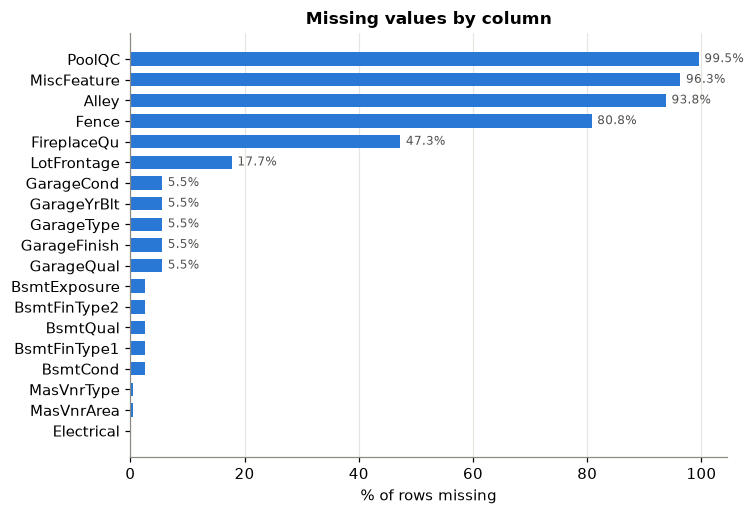

In [4]:
miss = df.isna().mean().mul(100)
miss = miss[miss > 0].sort_values()
print(f"{len(miss)} of {df.shape[1]} columns have missing values "
      f"({int(df.isna().sum().sum()):,} empty cells in total)")

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(miss.index, miss.values, color=BLUE, height=0.65)
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values by column")
ax.grid(axis="y", visible=False)
for name, v in miss.items():
    if v > 4:
        ax.text(v + 1, name, f"{v:.1f}%", va="center", fontsize=8, color="#52514e")
save(fig, "eda_missing_values")
plt.show()

In [5]:
# Which columns are *structurally* empty (feature absent) vs genuinely unknown?
related = {
    "Pool": ["PoolQC", "PoolArea"], "Garage": ["GarageType", "GarageCars", "GarageYrBlt"],
    "Basement": ["BsmtQual", "TotalBsmtSF"], "Fireplace": ["FireplaceQu", "Fireplaces"],
}
print("PoolQC missing where PoolArea == 0:     ", (df.PoolQC.isna() & (df.PoolArea == 0)).sum(),
      "of", df.PoolQC.isna().sum())
print("GarageType missing where GarageCars == 0:", (df.GarageType.isna() & (df.GarageCars == 0)).sum(),
      "of", df.GarageType.isna().sum())
print("BsmtQual missing where TotalBsmtSF == 0: ", (df.BsmtQual.isna() & (df.TotalBsmtSF == 0)).sum(),
      "of", df.BsmtQual.isna().sum())
print("FireplaceQu missing where Fireplaces == 0:", (df.FireplaceQu.isna() & (df.Fireplaces == 0)).sum(),
      "of", df.FireplaceQu.isna().sum())
print("\nGenuinely unknown (no 'absent' explanation):")
print("  LotFrontage:", df.LotFrontage.isna().sum(), "| MasVnrType:", df.MasVnrType.isna().sum(),
      "| Electrical:", df.Electrical.isna().sum())

PoolQC missing where PoolArea == 0:      1453 of 1453
GarageType missing where GarageCars == 0: 81 of 81
BsmtQual missing where TotalBsmtSF == 0:  37 of 37
FireplaceQu missing where Fireplaces == 0: 690 of 690

Genuinely unknown (no 'absent' explanation):
  LotFrontage: 259 | MasVnrType: 8 | Electrical: 1


**Insight.** Most "missing" cells are not missing data - they mean **"this house doesn't have one"**.
`PoolQC` is empty for 99.5% of rows because only 7 houses have a pool; the checks above show every
empty `PoolQC` lines up with `PoolArea == 0`, every empty `GarageType` with no garage, and so on.
Only three columns are *truly* unknown: `LotFrontage` (17.7%, 259 rows), `MasVnrType`/`MasVnrArea`
(8 rows) and `Electrical` (1 row).

**Decision.** (1) Fill structurally-absent categoricals with the explicit label `"None"` and absent
numerics with 0 - the model then *learns* "no garage" instead of seeing noise. (2) Impute truly
unknown values: `LotFrontage` by the median of its **neighborhood** (street frontage is similar
within a neighborhood), the rest by median / mode. (3) All imputation statistics are learned
inside the training fold only (no leakage).

## 3. Target distribution: why we log-transform `SalePrice`

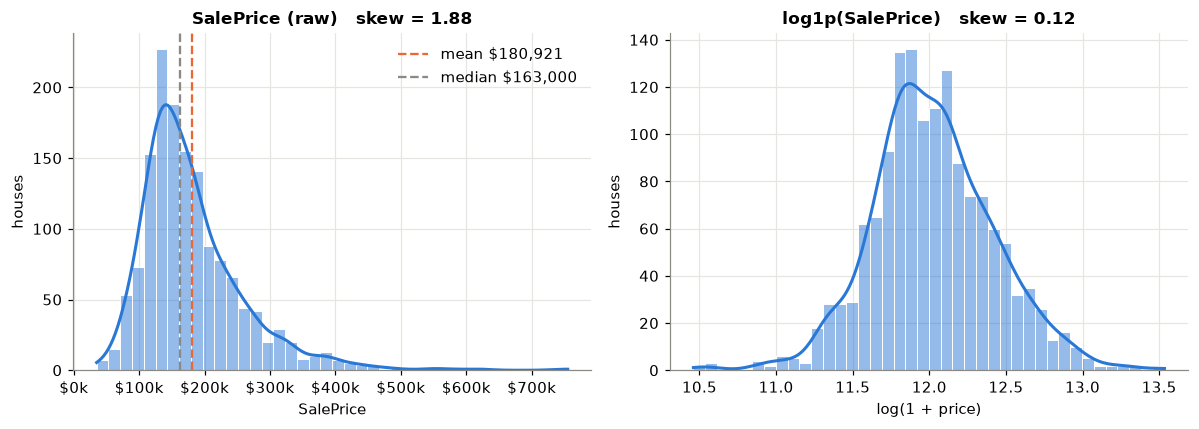

skew: raw = 1.883  ->  log1p = 0.121


In [6]:
y = df[TARGET]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, data, title, color in [
    (axes[0], y, "SalePrice (raw)", BLUE),
    (axes[1], np.log1p(y), "log1p(SalePrice)", BLUE),
]:
    sns.histplot(data, bins=40, kde=True, color=color, ax=ax, edgecolor="white", line_kws={"linewidth": 2})
    ax.set_title(f"{title}   skew = {data.skew():.2f}")
    ax.set_ylabel("houses")
axes[0].xaxis.set_major_formatter(usd_k)
axes[0].axvline(y.mean(), color=ORANGE, lw=1.5, ls="--", label=f"mean ${y.mean():,.0f}")
axes[0].axvline(y.median(), color=GRAY, lw=1.5, ls="--", label=f"median ${y.median():,.0f}")
axes[0].legend(frameon=False, loc="upper right")
axes[1].set_xlabel("log(1 + price)")
fig.tight_layout()
save(fig, "eda_target_distribution")
plt.show()
print(f"skew: raw = {y.skew():.3f}  ->  log1p = {np.log1p(y).skew():.3f}")

**Insight.** Prices are **right-skewed** (skew 1.88): most homes sit between ~$130k and ~$214k, but a
long tail of expensive homes (max $755k) drags the mean ($180.9k) above the median ($163k). After
`log1p` the skew falls to 0.12 and the histogram is close to a bell curve.

Why this matters for modelling:
1. Linear models assume roughly symmetric, constant-variance errors - the raw target violates that.
2. The tail would dominate a squared-error loss: one $700k miss outweighs dozens of small ones.
3. The competition metric (RMSLE) is the RMSE of log prices, so training on `log1p(price)` optimises
   exactly what we report. Errors become **relative** (a 10% miss counts the same on a $100k or a $400k house).

**Decision.** Train on `log1p(SalePrice)`, then invert with `expm1` to report prices in dollars.

## 4. Correlation heatmap

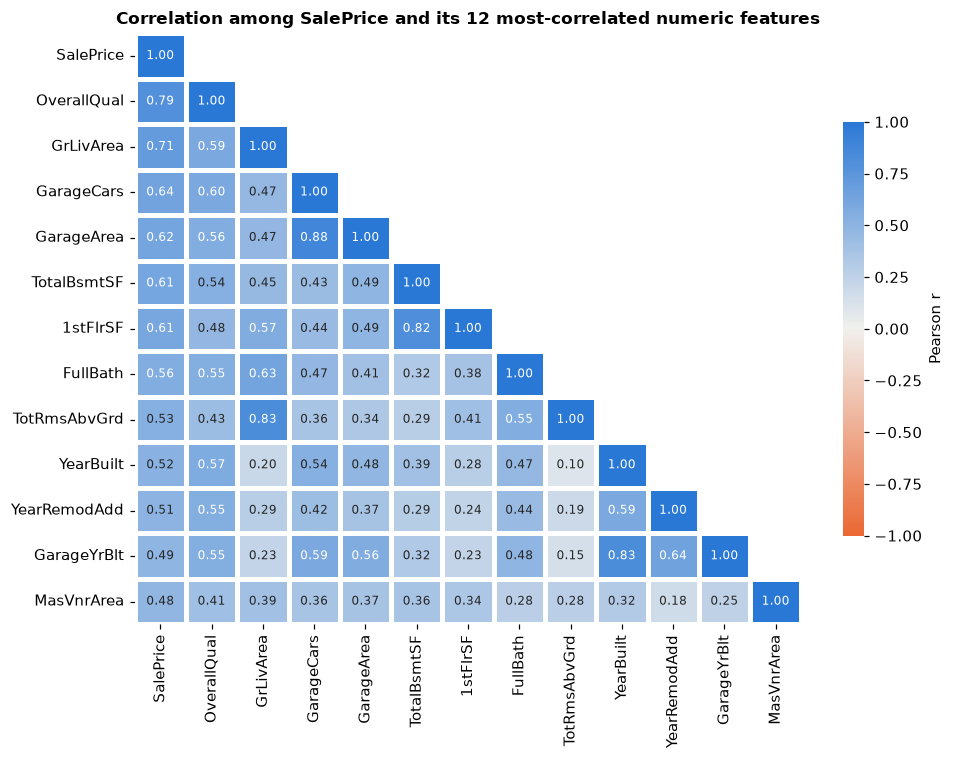

In [7]:
num = df.drop(columns="Id").select_dtypes("number")
top = num.corr()[TARGET].abs().sort_values(ascending=False).head(13).index
corr = num[top].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
cmap = LinearSegmentedColormap.from_list("div", [ORANGE, "#f1f0ed", BLUE])

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap=cmap, vmin=-1, vmax=1, linewidths=2,
            linecolor="white", cbar_kws={"shrink": 0.7, "label": "Pearson r"}, annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation among SalePrice and its 12 most-correlated numeric features")
ax.grid(False)
fig.tight_layout()
save(fig, "eda_correlation_heatmap")
plt.show()

**Insight.** `OverallQual` (r = 0.79) and `GrLivArea` (0.71) are the strongest linear signals, followed
by garage size, basement size and first-floor area (~0.6 each). Several features are near-duplicates of each other:
`GarageCars` vs `GarageArea` (0.88), `GrLivArea` vs `TotRmsAbvGrd` (0.83), `GarageYrBlt` vs `YearBuilt` (0.83),
`1stFlrSF` vs `TotalBsmtSF` (0.82).

**Decision.** Collinearity barely hurts tree models but destabilises plain linear regression, so the linear
baseline gets regularisation (Ridge). It also motivates *combined* features such as `TotalSF`
(basement + 1st + 2nd floor) instead of feeding in many overlapping areas.

## 5. Top 10 features vs price

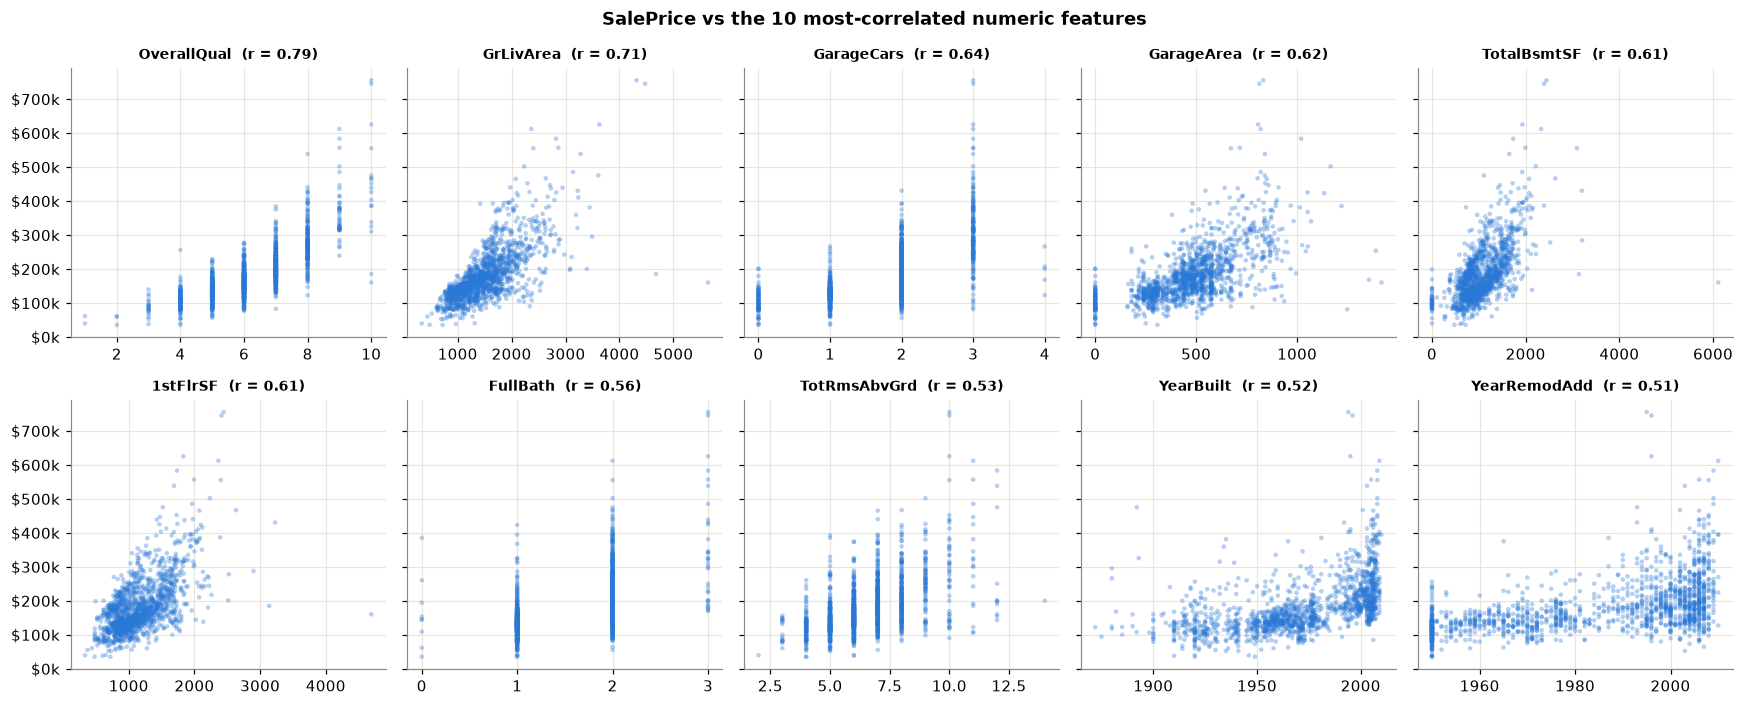

In [8]:
top10 = num.corr()[TARGET].drop(TARGET).abs().sort_values(ascending=False).head(10).index
fig, axes = plt.subplots(2, 5, figsize=(16, 6.5), sharey=True)
for ax, col in zip(axes.ravel(), top10):
    ax.scatter(df[col], y, s=9, alpha=0.35, color=BLUE, edgecolors="none")
    ax.set_title(f"{col}  (r = {df[col].corr(y):.2f})", fontsize=9)
    ax.yaxis.set_major_formatter(usd_k)
fig.suptitle("SalePrice vs the 10 most-correlated numeric features", fontweight="bold")
fig.tight_layout()
save(fig, "eda_top10_vs_price")
plt.show()

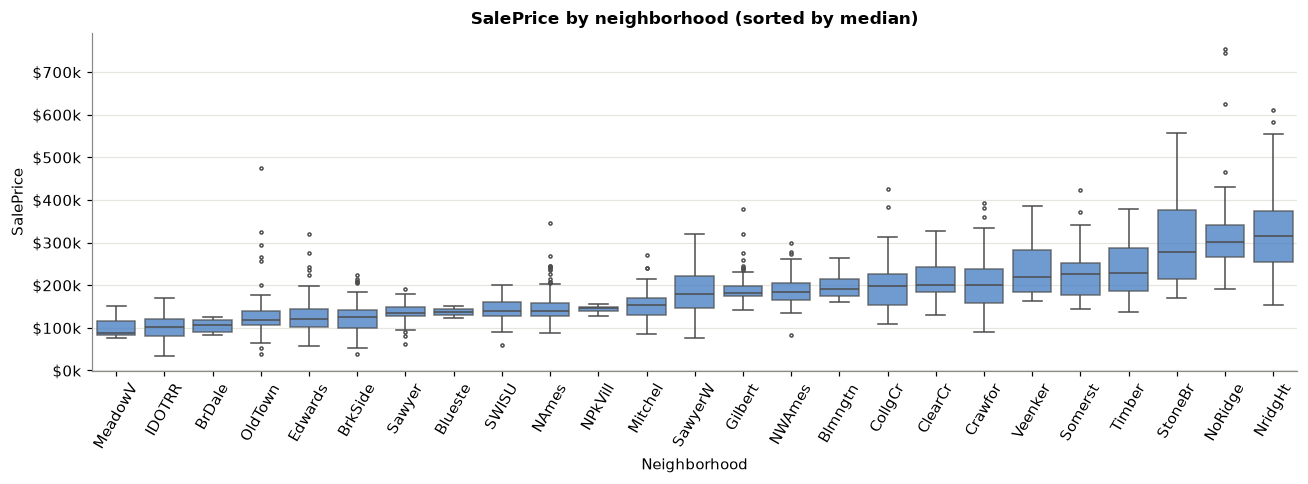

In [9]:
order = df.groupby("Neighborhood")[TARGET].median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=df, x="Neighborhood", y=TARGET, order=order, color=BLUE, fliersize=2,
            linewidth=1, boxprops={"alpha": 0.75}, ax=ax)
ax.yaxis.set_major_formatter(usd_k)
ax.set_title("SalePrice by neighborhood (sorted by median)")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "eda_neighborhood_boxplot")
plt.show()

**Insight.** Price rises with every one of these features, but not linearly:
- `OverallQual` is a clean staircase: median price goes from $133k at quality 5 to $200k at 7 to $345k at 9 -
  each quality step is worth a growing amount (consistent with a *multiplicative* effect, another reason for the log target).
- `GrLivArea`, `TotalBsmtSF` and `1stFlrSF` show a fan shape - variance grows with size, which log-transform also tames.
- `GarageCars`/`FullBath` are discrete with only a handful of values, and the pattern breaks at the edges: 3-car garages
  have a $295k median but the 5 houses with 4-car garages only $200k. Tiny groups like this are noisy, a reason to be careful
  about over-reading rare categories.
- Location matters a lot even though it is not in the numeric top 10: median price ranges from $88k (`MeadowV`)
  to $315k (`NridgHt`), and the quality/size features cannot explain that on their own.
- Several panels contain a few points far below the cloud (large area, low price) - examined next.

**Decision.** Keep `Neighborhood` as a (one-hot) categorical feature. Add `TotalSF`, `TotalBathrooms`, `HouseAge`
to capture the "bigger / newer / more bathrooms" patterns in single columns.

## 6. Outlier check: big houses with low prices

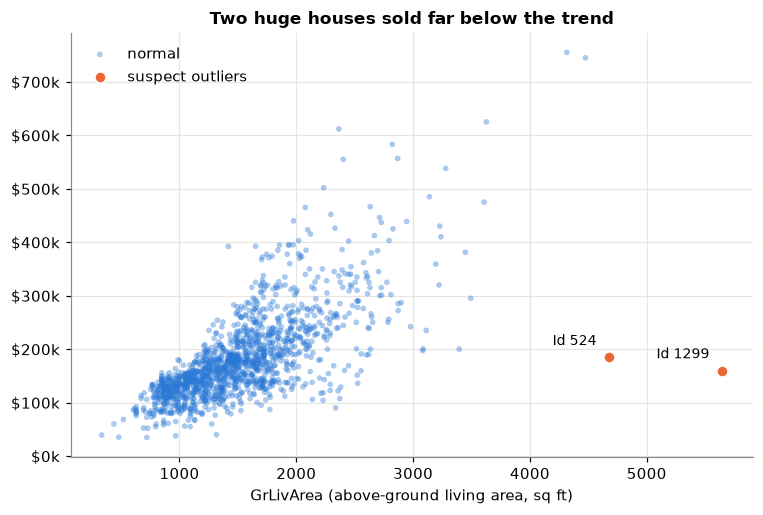

,Id,GrLivArea,SalePrice,SaleCondition,OverallQual,Neighborhood
523,524,4676,184750,Partial,10,Edwards
691,692,4316,755000,Normal,10,NoRidge
1182,1183,4476,745000,Abnorml,10,NoRidge
1298,1299,5642,160000,Partial,10,Edwards


In [10]:
is_out = (df.GrLivArea > 4000) & (df[TARGET] < 300_000)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df.GrLivArea[~is_out], y[~is_out], s=14, alpha=0.4, color=BLUE, edgecolors="none", label="normal")
ax.scatter(df.GrLivArea[is_out], y[is_out], s=60, color=ORANGE, edgecolors="white", linewidths=1.5,
           label="suspect outliers", zorder=3)
for _, r in df[is_out].iterrows():
    ax.annotate(f"Id {int(r.Id)}", (r.GrLivArea, r[TARGET]), textcoords="offset points", xytext=(-8, 8),
                ha="right", fontsize=9)
ax.yaxis.set_major_formatter(usd_k)
ax.set_xlabel("GrLivArea (above-ground living area, sq ft)")
ax.set_title("Two huge houses sold far below the trend")
ax.legend(frameon=False)
save(fig, "eda_outliers")
plt.show()
df.loc[df.GrLivArea > 4000, ["Id", "GrLivArea", TARGET, "SaleCondition", "OverallQual", "Neighborhood"]]

**Insight.** Four houses exceed 4,000 sq ft. Two (Id 692, 1183) sold for ~$750k - exactly what the trend predicts, so
they are *legitimate* extreme values. The other two (**Id 524: 4,676 sq ft for $184,750** and **Id 1299: 5,642 sq ft for
$160,000**) are priced like small houses, and both are `SaleCondition = Partial` (sold before construction was
finished - the price does not reflect the final house). The dataset's author flags exactly these as outliers.

These two rows look like errors of the *price*, not the house. Because a regression line is pulled toward extreme points,
leaving them in teaches the model that "huge area -> cheap", hurting predictions for ordinary large houses.

**Decision.** Remove only these two rows (rule: `GrLivArea > 4000` **and** `SalePrice < 300000`) from the data before
splitting. The rule is narrow on purpose - we do not trim the genuine $750k houses, which would hide the model's weakness
at the high end. This is reported in the README as a deliberate, documented choice.

## Summary: what the EDA tells the pipeline

| Finding | Action in the pipeline (Phase 3-4) |
|---|---|
| Target skew 1.88 -> 0.12 after log1p | Train on `log1p(SalePrice)`, invert with `expm1` |
| Most NaNs mean "feature absent" | Fill with `"None"` / 0, learned structurally - not statistically |
| `LotFrontage` 17.7% genuinely missing | Median by `Neighborhood`, fitted on training data only |
| `MSSubClass` is a code, not a number | Cast to category |
| Quality columns are ordered text | Ordinal encode Ex>Gd>TA>Fa>Po |
| Collinear area/garage features | Combined `TotalSF`, `TotalBathrooms`; Ridge for the linear baseline |
| Strong location effect | One-hot `Neighborhood` |
| 2 partial-sale mega-houses | Drop (`GrLivArea > 4000` and price < $300k) before the split |